#### CA3 – Extra Trees

Målet er å forutsi vinkvalitet ut fra kjemiske målinger.


#### Imports


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay

#### Settings


In [3]:
# Antall ulike oppdelinger vi tester
ET_test_runs = 10

# Beste innstillinger fra tidligere tester
best_params = {
    "n_estimators": 240,
    "criterion": "entropy",
    "min_samples_leaf": 2,
    "max_features": "sqrt"
}

# Grense for å klassifisere vin som god
threshold = 0.52


#### Reading data


In [4]:
df_wine = pd.read_csv("train.csv")
df_wine_test = pd.read_csv("test.csv")

print("Training data:", df_wine.shape)
print("Test data:", df_wine_test.shape)

df_wine.head()


Training data: (835, 13)
Test data: (209, 12)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id
0,7.8,0.610,0.29,1.6,0.114,9.0,29.0,0.99740,3.26,1.56,9.1,0,13
1,8.4,1.035,0.15,6.0,0.073,11.0,54.0,0.99900,3.37,0.49,9.9,0,705
2,8.1,0.290,0.36,2.2,0.048,35.0,53.0,0.99500,3.27,1.01,12.4,1,1408
3,5.2,0.340,0.00,1.8,0.050,27.0,63.0,0.99160,3.68,0.79,14.0,1,144
4,15.6,0.645,0.49,4.2,0.095,10.0,23.0,1.00315,2.92,0.74,11.1,0,557


#### Data exploration


In [5]:
# Sjekker om noen verdier mangler
print("Missing values in training data:")
print(df_wine.isna().sum())

print("\nMissing values in test data:")
print(df_wine_test.isna().sum())


Missing values in training data:
fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
Id                      0
dtype: int64

Missing values in test data:
fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
Id                      0
dtype: int64


In [6]:
# Ser på datatyper og statistikk
print(df_wine.dtypes)
df_wine.describe()


fixed acidity           float64
volatile acidity        float64
citric acid             float64
residual sugar          float64
chlorides               float64
free sulfur dioxide     float64
total sulfur dioxide    float64
density                 float64
pH                      float64
sulphates               float64
alcohol                 float64
quality                   int64
Id                        int64
dtype: object


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id
count,835.000000,835.000000,835.000000,835.000000,835.000000,835.000000,835.000000,835.000000,835.000000,835.000000,835.000000,835.000000,835.000000
mean,8.310898,0.540042,0.260790,2.542994,0.088674,15.859880,47.077246,0.996799,3.308707,0.658048,10.396287,0.500599,800.470659
std,1.757359,0.179786,0.197739,1.420451,0.051485,10.444733,33.271056,0.001946,0.159072,0.179891,1.087407,0.500299,468.873363
min,4.600000,0.120000,0.000000,0.900000,0.012000,1.000000,7.000000,0.990070,2.740000,0.330000,8.400000,0.000000,0.000000
25%,7.100000,0.410000,0.080000,1.900000,0.071000,7.000000,22.000000,0.995600,3.200000,0.550000,9.500000,0.000000,408.000000
50%,7.900000,0.540000,0.240000,2.200000,0.080000,13.000000,38.000000,0.996750,3.310000,0.610000,10.100000,1.000000,784.000000
75%,9.100000,0.647500,0.410000,2.600000,0.091000,21.000000,63.000000,0.997900,3.400000,0.725000,11.000000,1.000000,1225.500000
max,15.900000,1.580000,1.000000,15.500000,0.611000,68.000000,289.000000,1.003690,4.010000,2.000000,14.900000,1.000000,1597.000000


quality
0    417
1    418
Name: count, dtype: int64


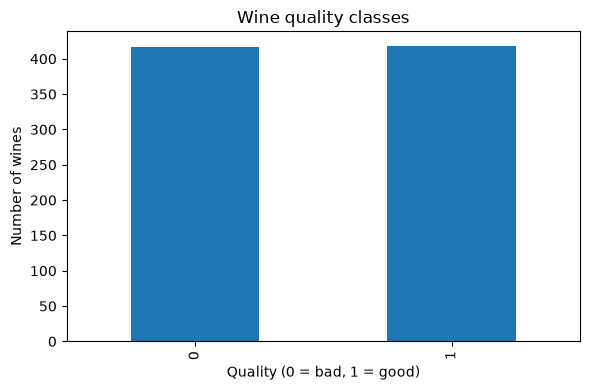

In [7]:
# Teller gode og dårlige viner
print(df_wine["quality"].value_counts().sort_index())

df_wine["quality"].value_counts().sort_index().plot.bar(figsize=(6, 4))
plt.title("Wine quality classes")
plt.xlabel("Quality (0 = bad, 1 = good)")
plt.ylabel("Number of wines")
plt.tight_layout()
plt.show()


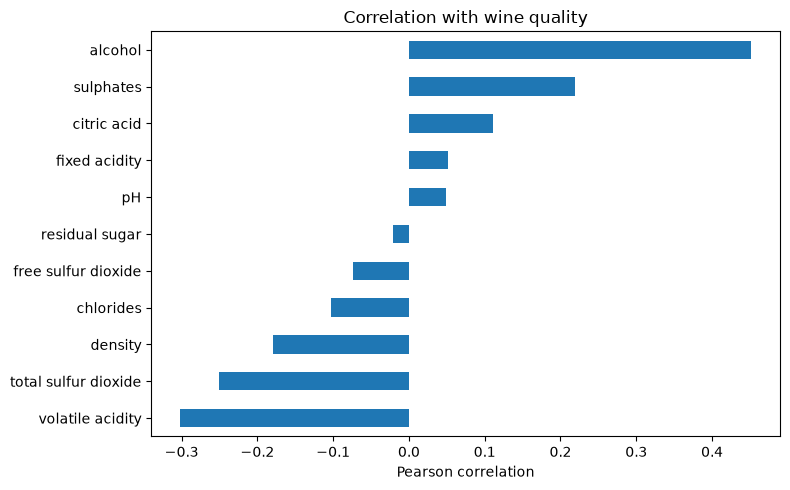

In [8]:
# Ser hvilke egenskaper som henger sammen med kvalitet
features = [column for column in df_wine_test.columns if column != "Id"]

correlations = df_wine[features + ["quality"]].corr()["quality"].drop("quality")
correlations.sort_values().plot.barh(figsize=(8, 5))
plt.title("Correlation with wine quality")
plt.xlabel("Pearson correlation")
plt.tight_layout()
plt.show()


#### Parameter comparison

Positiv korrelasjon betyr at høyere verdier ofte henger sammen med bedre vinkvalitet. Negativ korrelasjon betyr det motsatte.


In [9]:
# Sammenligner gjennomsnittet for de to klassene
class_means = df_wine.groupby("quality")[features].mean()
display(class_means.T)


quality,0,1
fixed acidity,8.220624,8.400957
volatile acidity,0.594412,0.485801
citric acid,0.238825,0.282703
residual sugar,2.572062,2.513995
chlorides,0.093995,0.083366
free sulfur dioxide,16.637890,15.083732
total sulfur dioxide,55.408873,38.765550
density,0.997148,0.996450
pH,3.300815,3.316579
sulphates,0.618561,0.697440


Alkohol har ofte positiv sammenheng med kvalitet, mens flyktig syre har negativ sammenheng. Vi beholder alle de 11 kjemiske egenskapene fordi Extra Trees kan finne mer kompliserte sammenhenger.


#### Data cleaning


In [10]:
# Skiller egenskaper fra fasiten
X = df_wine[features].copy()
y = df_wine["quality"].copy()
X_test = df_wine_test[features].copy()

# Sjekker at dataene passer sammen
assert X.columns.tolist() == X_test.columns.tolist()
assert not X.isna().any().any()
assert not X_test.isna().any().any()

print("Number of features:", X.shape[1])
print("Duplicate feature rows:", X.duplicated().sum())


Number of features: 11
Duplicate feature rows: 75


#### Visualisation


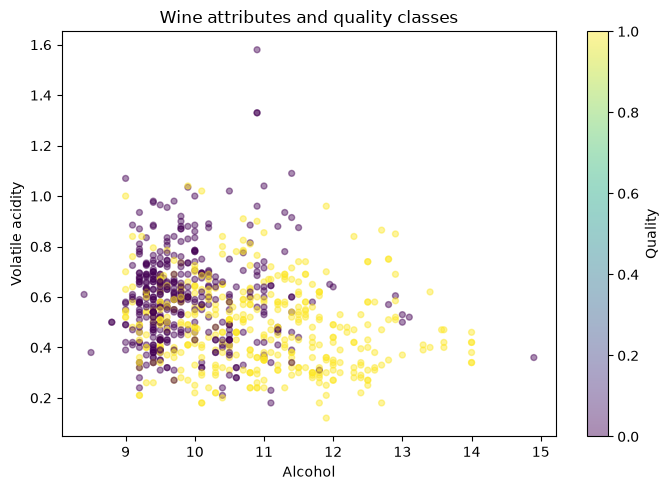

In [11]:
# Viser sammenhengen mellom alkohol og syre
plt.figure(figsize=(7, 5))
plt.scatter(df_wine["alcohol"], df_wine["volatile acidity"],
            c=df_wine["quality"], alpha=0.45, s=18)
plt.xlabel("Alcohol")
plt.ylabel("Volatile acidity")
plt.title("Wine attributes and quality classes")
plt.colorbar(label="Quality")
plt.tight_layout()
plt.show()


#### Extra Trees trials


In [12]:
# Tester flere innstillinger på ulike oppdelinger
ET_parameters = [
    {"n_estimators": 100, "criterion": "gini", "min_samples_leaf": 1},
    {"n_estimators": 200, "criterion": "entropy", "min_samples_leaf": 1},
    {"n_estimators": 240, "criterion": "entropy", "min_samples_leaf": 2},
    {"n_estimators": 300, "criterion": "entropy", "min_samples_leaf": 3},
]

results = []

for params in ET_parameters:
    scores = []

    for state in range(ET_test_runs):
        X_train, X_val, y_train, y_val = train_test_split(
            X, y, test_size=0.25, random_state=state, stratify=y
        )

        clf = ExtraTreesClassifier(
            **params, max_features="sqrt", random_state=42, n_jobs=1
        )
        clf.fit(X_train, y_train)
        scores.append(accuracy_score(y_val, clf.predict(X_val)))

    results.append({**params, "mean_accuracy": np.mean(scores)})

results_table = pd.DataFrame(results).sort_values(
    "mean_accuracy", ascending=False
)
print(results_table.to_string(index=False))


 n_estimators criterion  min_samples_leaf  mean_accuracy
          240   entropy                 2       0.769856
          100      gini                 1       0.766507
          200   entropy                 1       0.765550
          300   entropy                 3       0.758852


#### Model evaluation


In [13]:
# Kontrollerer den valgte modellen på nye oppdelinger
validation_scores = []

for state in range(100, 120):
    X_train, X_val, y_train, y_val = train_test_split(
        X, y, test_size=0.25, random_state=state, stratify=y
    )

    clf = ExtraTreesClassifier(**best_params, random_state=42, n_jobs=1)
    clf.fit(X_train, y_train)

    probabilities = clf.predict_proba(X_val)[:, 1]
    predicted_quality = (probabilities >= threshold).astype(int)
    validation_scores.append(accuracy_score(y_val, predicted_quality))

print(f"Mean validation accuracy: {np.mean(validation_scores):.2%}")
print(f"Standard deviation: {np.std(validation_scores):.2%}")


Mean validation accuracy: 77.03%
Standard deviation: 2.13%


#### Kaggle export


In [14]:
# Trener modellen på alle treningsdataene
final_model = ExtraTreesClassifier(**best_params, random_state=42, n_jobs=1)
final_model.fit(X, y)

# Lager prediksjoner til Kaggle
probabilities = final_model.predict_proba(X_test)[:, 1]
predictions = (probabilities >= threshold).astype(int)

submission = pd.DataFrame({
    "Id": np.arange(len(X_test)),
    "TARGET": predictions
})

submission.to_csv("CA3_ExtraTrees_submission.csv", index=False)
print(submission.head())
print("Saved CA3_ExtraTrees_submission.csv")


   Id  TARGET
0   0       1
1   1       1
2   2       0
3   3       0
4   4       0
Saved CA3_ExtraTrees_submission.csv
